# K2 NDVI phenology at field plots — first spring maximum → subsequent minimum

Samples **plot locations only** from annual K2 intercept–amplitude–phase GeoTIFFs (no wall-to-wall processing or exports). Selects the **first qualifying local NDVI maximum** in a prespecified spring window, followed by its **first subsequent local minimum**. Measures timing, peak-to-trough decline, decline duration, and rate. Flags missing/weak extrema; shows fitted curves with marked events and distribution plots.

**Caution:** The phase convention and time origin must match the Earth Engine harmonic export. Verify against observed NDVI at several plots. No phenology classifier is fitted here. A periodic K2 curve is a smooth approximation, not an observation of plant phenology.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from pyproj import Transformer
from IPython.display import display

HARMONIC_ROOT = Path(r"A:\NCA_DATA\S2_Harmonics")
POINTS_CSV = Path(r"A:\NCA_DATA\Validation\Supervised_State_Classification\FieldVeg_K2_IA45_Training.csv")
YEARS = list(range(2016, 2027))  # 2026 included automatically once data exist
# Field table must contain plot coordinates; update names below after inspecting printed columns.
PLOT_ID_COL = 'PlotID'
YEAR_COL = 'Year'
X_COL = 'Easting'
Y_COL = 'Northing'
POINT_CRS = 'EPSG:26911'  # update if source coordinates are lon/lat (EPSG:4326)
# IMPORTANT: inspect the TIFF band names and confirm how phase was calculated.
# For y = c + A cos(wt - phi), choose 'cos_minus'.
# For y = c + A cos(wt + phi), choose 'cos_plus'.
# For y = c + A sin(wt + phi), choose 'sin_plus'.
PHASE_CONVENTION = 'cos_minus'
PHASE_UNITS = 'radians'  # or 'degrees'
TIME_ORIGIN_DOY = 1  # must agree with export's Fourier time origin
# Predeclared phenological windows; evaluate sensitivity before selecting any final features.
SPRING_PEAK_WINDOW = (30, 180)     # DOY inclusive; candidate early-season peaks
SUMMER_TROUGH_END_DOY = 300        # no minimum after this day
MAX_DECLINE_DAYS = 180             # require subsequent trough within 180 days
MIN_PEAK_PROMINENCE_FRACTION = 0.10 # relative to full fitted annual NDVI range
MIN_RANGE = 0.025                 # QC threshold in NDVI; not ecological significance
DOY = np.arange(1, 366)


In [2]:
points = pd.read_csv(POINTS_CSV, low_memory=False)
print('Columns:', list(points.columns))
required = [PLOT_ID_COL, YEAR_COL, X_COL, Y_COL]
missing = [c for c in required if c not in points.columns]
if missing:
    raise KeyError(f'Missing plot columns {missing}. Set X_COL, Y_COL, POINT_CRS above based on printed columns.')
points = points.dropna(subset=required).copy()
points[YEAR_COL] = pd.to_numeric(points[YEAR_COL], errors='coerce')
points = points[points[YEAR_COL].isin(YEARS)].copy()
points = points.drop_duplicates(subset=[PLOT_ID_COL, YEAR_COL])
print('Plot-years:', len(points)); display(points[required].head())


Columns: ['PlotID', 'Year', 'Easting', 'Northing', 'parent_cluster', 'parent_label', 'max_membership', 'second_membership', 'membership_margin', 'membership_1', 'membership_2', 'membership_3', 'membership_4', 'membership_5', 'membership_6', 'membership_7', 'membership_8', 'raw_subcluster', 'state_id', 'state_label', 'state_type', 'is_reference', 'nobs', 'constant_B2', 'constant_B3', 'constant_B4', 'constant_B5', 'constant_B6', 'constant_B7', 'constant_B8', 'constant_B8A', 'constant_B11', 'constant_B12', 'constant_NDVI', 'constant_NDMI', 'constant_NDRE', 'constant_BSI', 'constant_NBR2', 'amp1_B2', 'amp1_B3', 'amp1_B4', 'amp1_B5', 'amp1_B6', 'amp1_B7', 'amp1_B8', 'amp1_B8A', 'amp1_B11', 'amp1_B12', 'amp1_NDVI', 'amp1_NDMI', 'amp1_NDRE', 'amp1_BSI', 'amp1_NBR2', 'amp2_B2', 'amp2_B3', 'amp2_B4', 'amp2_B5', 'amp2_B6', 'amp2_B7', 'amp2_B8', 'amp2_B8A', 'amp2_B11', 'amp2_B12', 'amp2_NDVI', 'amp2_NDMI', 'amp2_NDRE', 'amp2_BSI', 'amp2_NBR2']
Plot-years: 479


,PlotID,Year,Easting,Northing
0,100,2016,589959.8600,4.767951e+06
1,101,2016,590024.1050,4.767835e+06
2,102,2016,593417.5396,4.768936e+06
3,103,2016,593400.7996,4.768939e+06
4,104,2016,594390.5446,4.768703e+06


In [3]:
def annual_path(year):
    return HARMONIC_ROOT / str(year) / f'{year}_K2_InterceptAmpPhase_nobs_RMSE.tif'

def band_names(src):
    return [str(x or f'band_{i}').strip() for i, x in enumerate(src.descriptions, 1)]

for yr in YEARS:
    path = annual_path(yr)
    if path.exists():
        with rasterio.open(path) as ds:
            print('Example TIFF:', path, '| CRS:', ds.crs)
            print('NDVI-related bands:', [(i, s) for i,s in enumerate(band_names(ds),1) if 'ndvi' in s.lower()])
        break
else:
    raise FileNotFoundError('No annual K2 TIFF found; verify HARMONIC_ROOT.')


Example TIFF: A:\NCA_DATA\S2_Harmonics\2016\2016_K2_InterceptAmpPhase_nobs_RMSE.tif | CRS: PROJCS["NAD83 / UTM zone 11N",GEOGCS["NAD83",DATUM["North American Datum 1983",SPHEROID["GRS 1980",6378137,298.257222101004]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
NDVI-related bands: [(11, 'constant_NDVI'), (26, 'amp1_NDVI'), (41, 'phase1_NDVI'), (56, 'amp2_NDVI'), (71, 'phase2_NDVI'), (87, 'RMSE_NDVI')]


In [4]:
def resolve_ndvi_bands(src):
    # Requires explicit NDVI intercept, amplitude 1/2 and phase 1/2.
    # Prevents silently using phase from a different index/order.
    names = band_names(src)
    groups = {
        'beta0': [r'^(constant|intercept|beta0)[_-]ndvi$', r'^ndvi[_-](constant|intercept|beta0)$'],
        'a1': [r'^(amp1|amplitude1|amp_1)[_-]ndvi$', r'^ndvi[_-](amp1|amplitude1|amp_1)$'],
        'a2': [r'^(amp2|amplitude2|amp_2)[_-]ndvi$', r'^ndvi[_-](amp2|amplitude2|amp_2)$'],
        'p1': [r'^(phase1|phase_1|phi1|phi_1)[_-]ndvi$', r'^ndvi[_-](phase1|phase_1|phi1|phi_1)$'],
        'p2': [r'^(phase2|phase_2|phi2|phi_2)[_-]ndvi$', r'^ndvi[_-](phase2|phase_2|phi2|phi_2)$'],
    }
    idx = {}
    for key, patterns in groups.items():
        match = [i for i,name in enumerate(names, 1) if any(re.fullmatch(pt,name.lower()) for pt in patterns)]
        if len(match) != 1:
            raise ValueError(f'{key}: expected one NDVI band, got {match}. Available NDVI bands: '
                             +repr([(i,s) for i,s in enumerate(names,1) if 'ndvi' in s.lower()]))
        idx[key] = match[0]
    return idx

def sample_year(df, year):
    path=annual_path(year)
    if not path.exists():
        print(f'Skipping {year}: no raster')
        return pd.DataFrame()
    with rasterio.open(path) as ds:
        ix=resolve_ndvi_bands(ds)
        xy=df[[X_COL,Y_COL]].apply(pd.to_numeric,errors='coerce').to_numpy(float)
        if not np.isfinite(xy).all():
            raise ValueError(f'Invalid plot coordinates for {year}')
        if str(ds.crs) != str(POINT_CRS):
            t=Transformer.from_crs(POINT_CRS,ds.crs,always_xy=True)
            xy=np.array([t.transform(x,y) for x,y in xy])
        coords=list(map(tuple,xy))
        # Only 5 bands at selected points; never reads complete raster.
        vals=np.asarray(list(ds.sample(coords,indexes=list(ix.values()),masked=True)))
        values=np.ma.filled(vals.astype(float),np.nan)
        result=df[[PLOT_ID_COL,YEAR_COL]].copy().reset_index(drop=True)
        for j,key in enumerate(ix): result[key]=values[:,j]
        result['in_bounds']=[ds.bounds.left<=x<=ds.bounds.right and ds.bounds.bottom<=y<=ds.bounds.top for x,y in coords]
        result.loc[~result['in_bounds'],list(ix)] = np.nan
        return result

frames=[]
for year in YEARS:
    sub=points[points[YEAR_COL].eq(year)]
    if len(sub):
        sampled=sample_year(sub,year)
        if len(sampled): frames.append(sampled)
if not frames: raise RuntimeError('No plot-year samples available.')
sampled=pd.concat(frames,ignore_index=True)
valid=np.isfinite(sampled[['beta0','a1','a2','p1','p2']]).all(axis=1)
print(f'Complete phase/amp fits: {valid.sum()} / {len(sampled)}')
display(sampled.head())


Complete phase/amp fits: 479 / 479


,PlotID,Year,beta0,a1,a2,p1,p2,in_bounds
0,100,2016,0.126941,0.079495,0.031102,1.320598,2.965630,True
1,101,2016,0.155435,0.106519,0.026460,0.934430,2.119081,True
2,102,2016,0.140608,0.036501,0.010803,1.133071,-2.332327,True
3,103,2016,0.138169,0.036057,0.011567,1.160019,-2.061493,True
4,104,2016,0.151693,0.063852,0.022509,1.322101,2.877918,True


In [5]:
def reconstruct_ndvi(rec, doy=DOY):
    t = np.asarray(doy, dtype=float) - TIME_ORIGIN_DOY
    theta = 2 * np.pi * t / 365.0
    p1, p2 = float(rec['p1']), float(rec['p2'])
    if PHASE_UNITS == 'degrees':
        p1, p2 = np.deg2rad([p1, p2])
    if PHASE_CONVENTION == 'cos_minus':
        v = rec['beta0'] + rec['a1'] * np.cos(theta - p1) + rec['a2'] * np.cos(2 * theta - p2)
    elif PHASE_CONVENTION == 'cos_plus':
        v = rec['beta0'] + rec['a1'] * np.cos(theta + p1) + rec['a2'] * np.cos(2 * theta + p2)
    elif PHASE_CONVENTION == 'sin_plus':
        v = rec['beta0'] + rec['a1'] * np.sin(theta + p1) + rec['a2'] * np.sin(2 * theta + p2)
    else:
        raise ValueError('Unknown PHASE_CONVENTION')
    return np.asarray(v, dtype=float)


def first_spring_peak_and_trough(v):
    """Find first meaningful spring local maximum and next summer local minimum.

    Extrema use circular neighbors (Fourier curve is periodic), but their selection
    uses explicit calendar-day windows. First qualifying candidate is selected.
    Qualifying means the drop to the NEXT local minimum exceeds a prespecified
    fraction of annual fitted range. This avoids selecting insignificant ripples.
    """
    v = np.asarray(v, dtype=float)
    if v.shape != (365,) or not np.isfinite(v).all():
        return None
    annual_range = float(np.ptp(v))
    if annual_range < MIN_RANGE:
        return None
    maxima = np.flatnonzero((v > np.roll(v, 1)) & (v >= np.roll(v, -1)))
    minima = np.flatnonzero((v < np.roll(v, 1)) & (v <= np.roll(v, -1)))
    for peak in maxima:  # sorted earliest DOY first
        peak_doy = int(peak + 1)
        if not SPRING_PEAK_WINDOW[0] <= peak_doy <= SPRING_PEAK_WINDOW[1]:
            continue
        next_minima = [i for i in minima if
                       peak < i and (i - peak) <= MAX_DECLINE_DAYS
                       and (i + 1) <= SUMMER_TROUGH_END_DOY]
        if not next_minima:
            continue
        trough = int(next_minima[0])
        decline = float(v[peak] - v[trough])
        if decline >= MIN_PEAK_PROMINENCE_FRACTION * annual_range:
            return int(peak), trough
    return None


def phenology_metrics(rec):
    v = reconstruct_ndvi(rec)
    annual_range = float(np.ptp(v))
    event = first_spring_peak_and_trough(v)
    out = {
        'spring_peak_doy': np.nan,
        'summer_min_doy': np.nan,
        'spring_peak_ndvi_fit': np.nan,
        'summer_min_ndvi_fit': np.nan,
        'decline_duration_days': np.nan,
        'decline_magnitude_ndvi': np.nan,
        'mean_decline_rate_ndvi_day': np.nan,
        'max_decline_rate_ndvi_day': np.nan,
        'ndvi_range_fit': annual_range,
        'weak_seasonality': annual_range < MIN_RANGE,
        'valid_spring_decline': event is not None,
        'global_peak_doy_qc': int(np.argmax(v)) + 1,
    }
    if event is None:
        return pd.Series(out)
    peak, trough = event
    duration = trough - peak
    daily_change = np.diff(v[peak:trough+1])
    decline = float(v[peak] - v[trough])
    out.update({
        'spring_peak_doy': peak + 1,
        'summer_min_doy': trough + 1,
        'spring_peak_ndvi_fit': float(v[peak]),
        'summer_min_ndvi_fit': float(v[trough]),
        'decline_duration_days': duration,
        'decline_magnitude_ndvi': decline,
        'mean_decline_rate_ndvi_day': decline / duration,
        'max_decline_rate_ndvi_day': float(-daily_change.min()),
    })
    return pd.Series(out)


valid_sample = sampled.loc[valid].copy().reset_index(drop=True)
metrics = valid_sample.apply(phenology_metrics, axis=1)
plot_features = pd.concat([valid_sample, metrics], axis=1)
fields = ['spring_peak_doy', 'summer_min_doy', 'decline_duration_days',
          'decline_magnitude_ndvi', 'mean_decline_rate_ndvi_day',
          'max_decline_rate_ndvi_day']
print(f'Plot-years: {len(plot_features)}; qualifying spring decline: '
      f'{plot_features.valid_spring_decline.sum()} '
      f'({plot_features.valid_spring_decline.mean():.1%})')
display(plot_features.groupby(YEAR_COL)[fields].agg(['count','median']))
display(plot_features[[PLOT_ID_COL, YEAR_COL, 'valid_spring_decline', *fields]].head())


Plot-years: 479; qualifying spring decline: 448 (93.5%)


spring_peak_doy        summer_min_doy        decline_duration_days  \
               count median          count median                 count   
Year                                                                      
2016             230   76.0            230  215.0                   230   
2018             104   74.0            104  202.0                   104   
2025             114  113.0            114  219.5                   114   

            decline_magnitude_ndvi           mean_decline_rate_ndvi_day  \
     median                  count    median                      count   
Year                                                                      
2016  133.0                    230  0.142308                        230   
2018  124.0                    104  0.208889                        104   
2025  105.0                    114  0.122353                        114   

               max_decline_rate_ndvi_day            
        median                     count    median  
Year                                                
2016  0.001069                       230  0.001732  
2018  0.001722                       104  0.002808  
2025  0.001133                       114  0.001846

,PlotID,Year,valid_spring_decline,spring_peak_doy,summer_min_doy,decline_duration_days,decline_magnitude_ndvi,mean_decline_rate_ndvi_day,max_decline_rate_ndvi_day
0,100,2016,True,83.0,213.0,130.0,0.176118,0.001355,0.002241
1,101,2016,True,59.0,210.0,151.0,0.217710,0.001442,0.002483
2,102,2016,True,92.0,227.0,135.0,0.082695,0.000613,0.001000
3,103,2016,True,98.0,231.0,133.0,0.082618,0.000621,0.001013
4,104,2016,True,82.0,216.0,134.0,0.136482,0.001019,0.001696


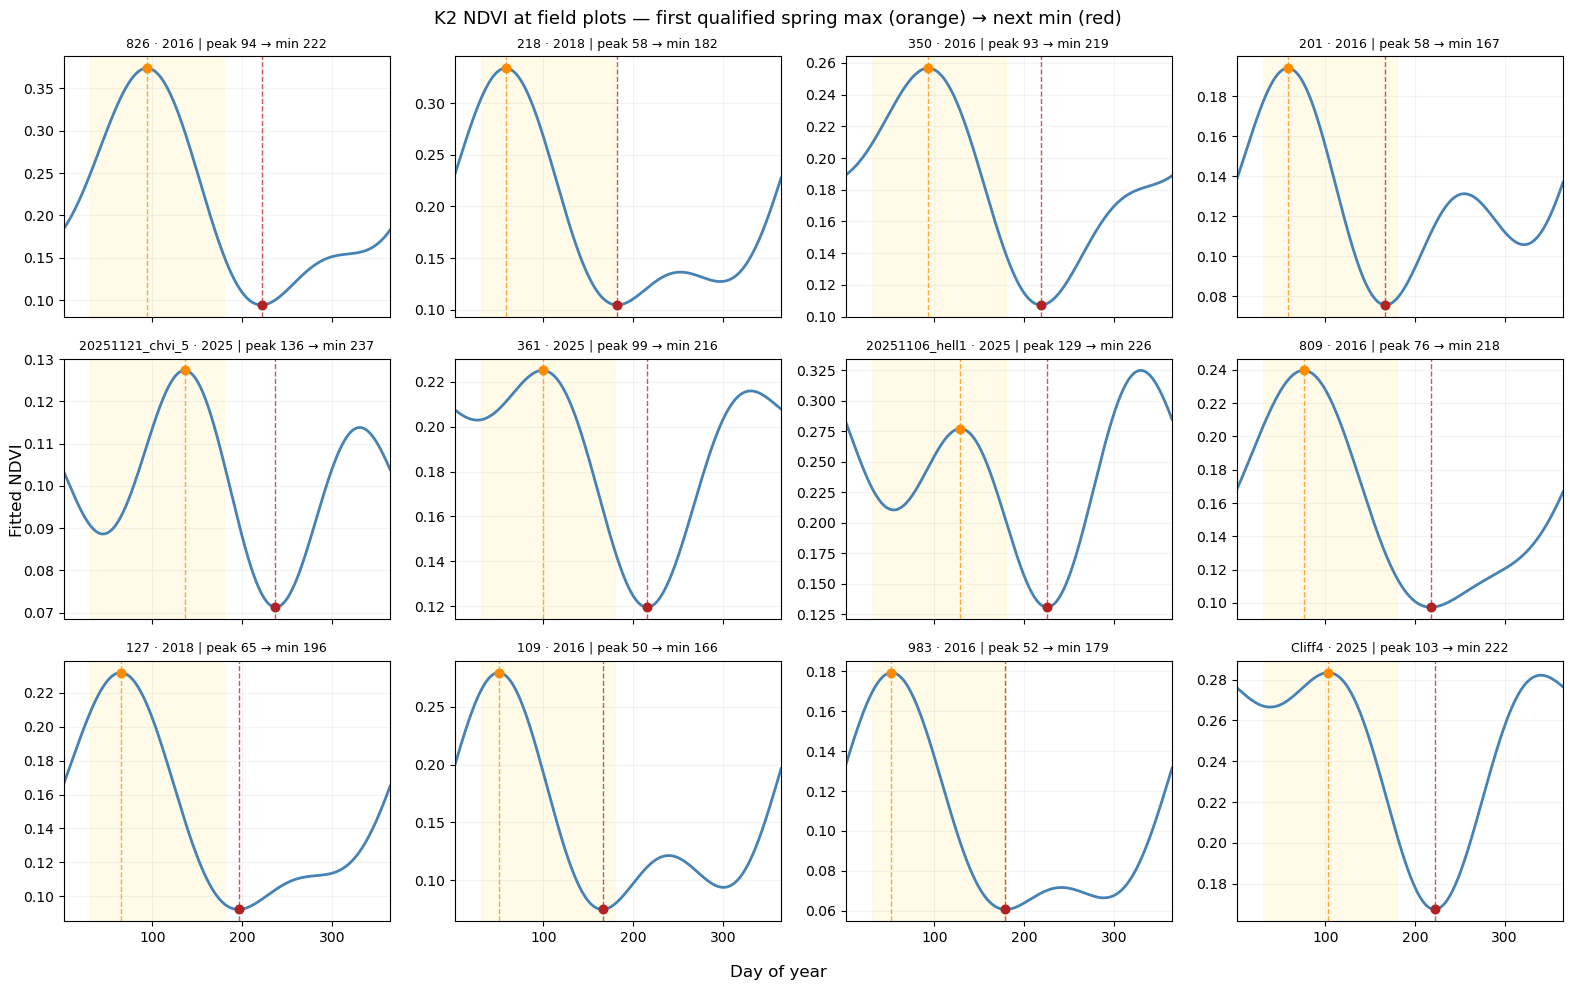

In [6]:
# Seasonal reconstructions with explicitly selected peak and subsequent trough.
# Include valid and unqualified curves so selection failures remain visible.
sub = plot_features.sample(n=min(12, len(plot_features)), random_state=42)
fig, axes = plt.subplots(3, 4, figsize=(16, 10), sharex=True)
for ax, (_, rec) in zip(axes.flat, sub.iterrows()):
    v = reconstruct_ndvi(rec)
    ax.plot(DOY, v, color='steelblue', lw=2)
    ax.axvspan(*SPRING_PEAK_WINDOW, color='gold', alpha=0.09)
    if rec.valid_spring_decline:
        p, m = int(rec.spring_peak_doy), int(rec.summer_min_doy)
        ax.scatter([p], [v[p-1]], color='darkorange', s=38, zorder=3)
        ax.scatter([m], [v[m-1]], color='firebrick', s=38, zorder=3)
        ax.axvline(p, color='darkorange', lw=1, ls='--', alpha=.75)
        ax.axvline(m, color='firebrick', lw=1, ls='--', alpha=.75)
        subtitle = f'peak {p} → min {m}'
    else:
        subtitle = 'no qualifying spring decline'
    ax.set_title(f'{rec[PLOT_ID_COL]} · {int(rec[YEAR_COL])} | {subtitle}', fontsize=9)
    ax.set_xlim(1, 365)
    ax.grid(alpha=.15)
for ax in axes.flat[len(sub):]:
    ax.axis('off')
fig.suptitle('K2 NDVI at field plots — first qualified spring max (orange) → next min (red)', fontsize=13)
fig.supxlabel('Day of year')
fig.supylabel('Fitted NDVI')
plt.tight_layout()
plt.show()


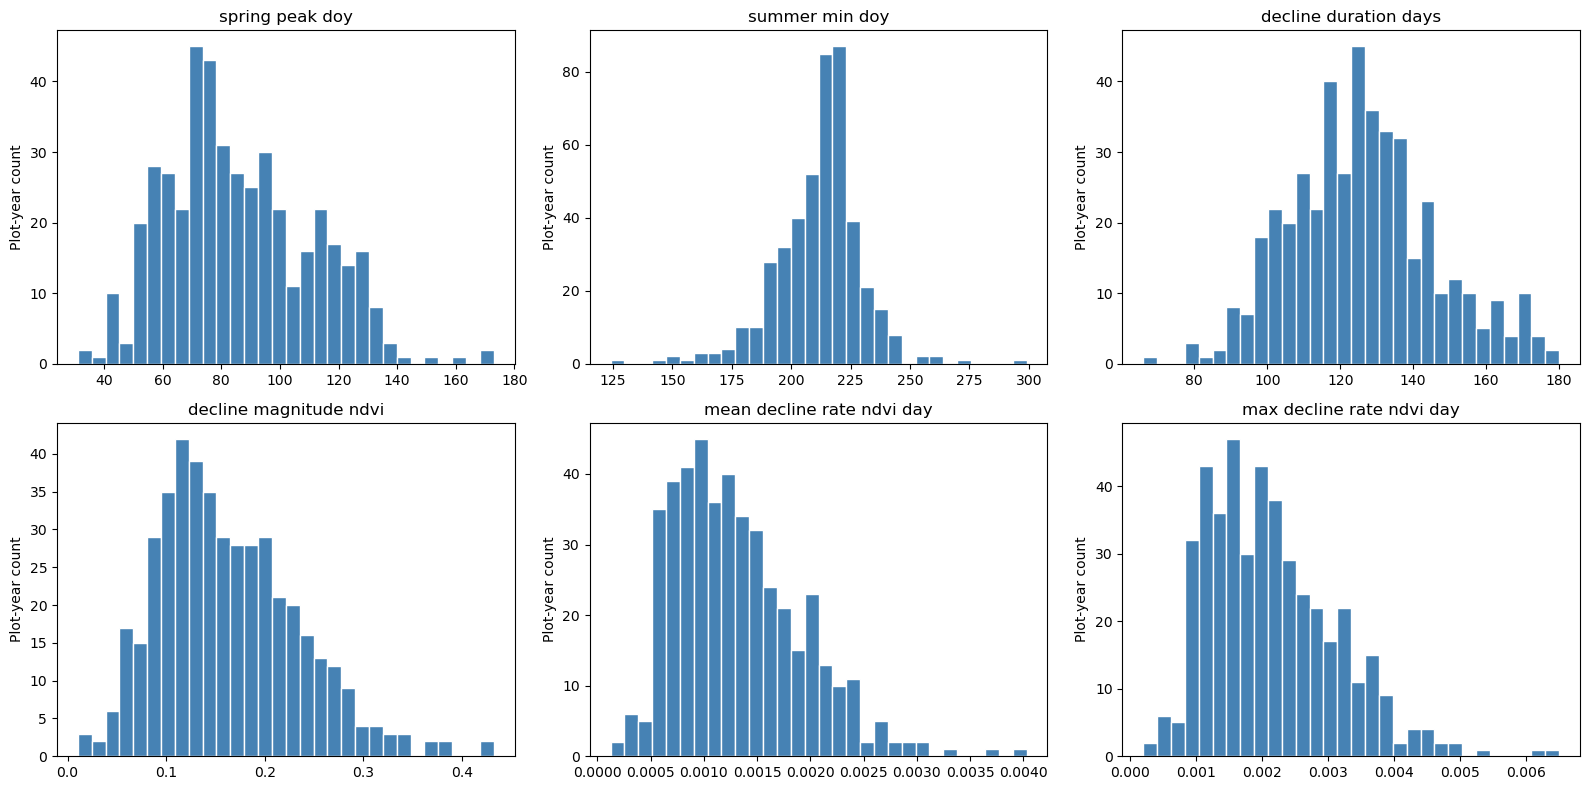

Spring peak differs from global peak: 7.8%
Consecutive plot-year pairs: 0 | with valid peaks: 0


In [7]:
# Distributions of spring maximum, subsequent minimum, and decline behavior.
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, fields):
    x = plot_features.loc[plot_features.valid_spring_decline, col].dropna()
    ax.hist(x, bins=30, edgecolor='white', color='steelblue')
    ax.set_title(col.replace('_', ' '))
    ax.set_ylabel('Plot-year count')
plt.tight_layout()
plt.show()

# QC: how often did the first spring maximum differ from the global maximum?
qualified = plot_features.loc[plot_features.valid_spring_decline]
print('Spring peak differs from global peak:',
      f'{(qualified.spring_peak_doy != qualified.global_peak_doy_qc).mean():.1%}'
      if len(qualified) else 'No qualified plots')

# Repeated plot locations in consecutive observed years (if any).
repeat = plot_features.sort_values([PLOT_ID_COL, YEAR_COL]).copy()
repeat['previous_year'] = repeat.groupby(PLOT_ID_COL)[YEAR_COL].shift()
repeat['previous_spring_peak'] = repeat.groupby(PLOT_ID_COL)['spring_peak_doy'].shift()
repeat = repeat.loc[(repeat[YEAR_COL] - repeat.previous_year) == 1].copy()
repeat['spring_peak_shift_days'] = repeat.spring_peak_doy - repeat.previous_spring_peak
print('Consecutive plot-year pairs:', len(repeat),
      '| with valid peaks:', repeat.spring_peak_shift_days.notna().sum())
if repeat.spring_peak_shift_days.notna().any():
    display(repeat.spring_peak_shift_days.describe())
    plt.figure(figsize=(8, 3))
    plt.hist(repeat.spring_peak_shift_days.dropna(), bins=30, color='steelblue')
    plt.title('Interannual spring-peak DOY difference (same plot, consecutive years)')
    plt.xlabel('Difference in days')
    plt.ylabel('Pairs')
    plt.show()


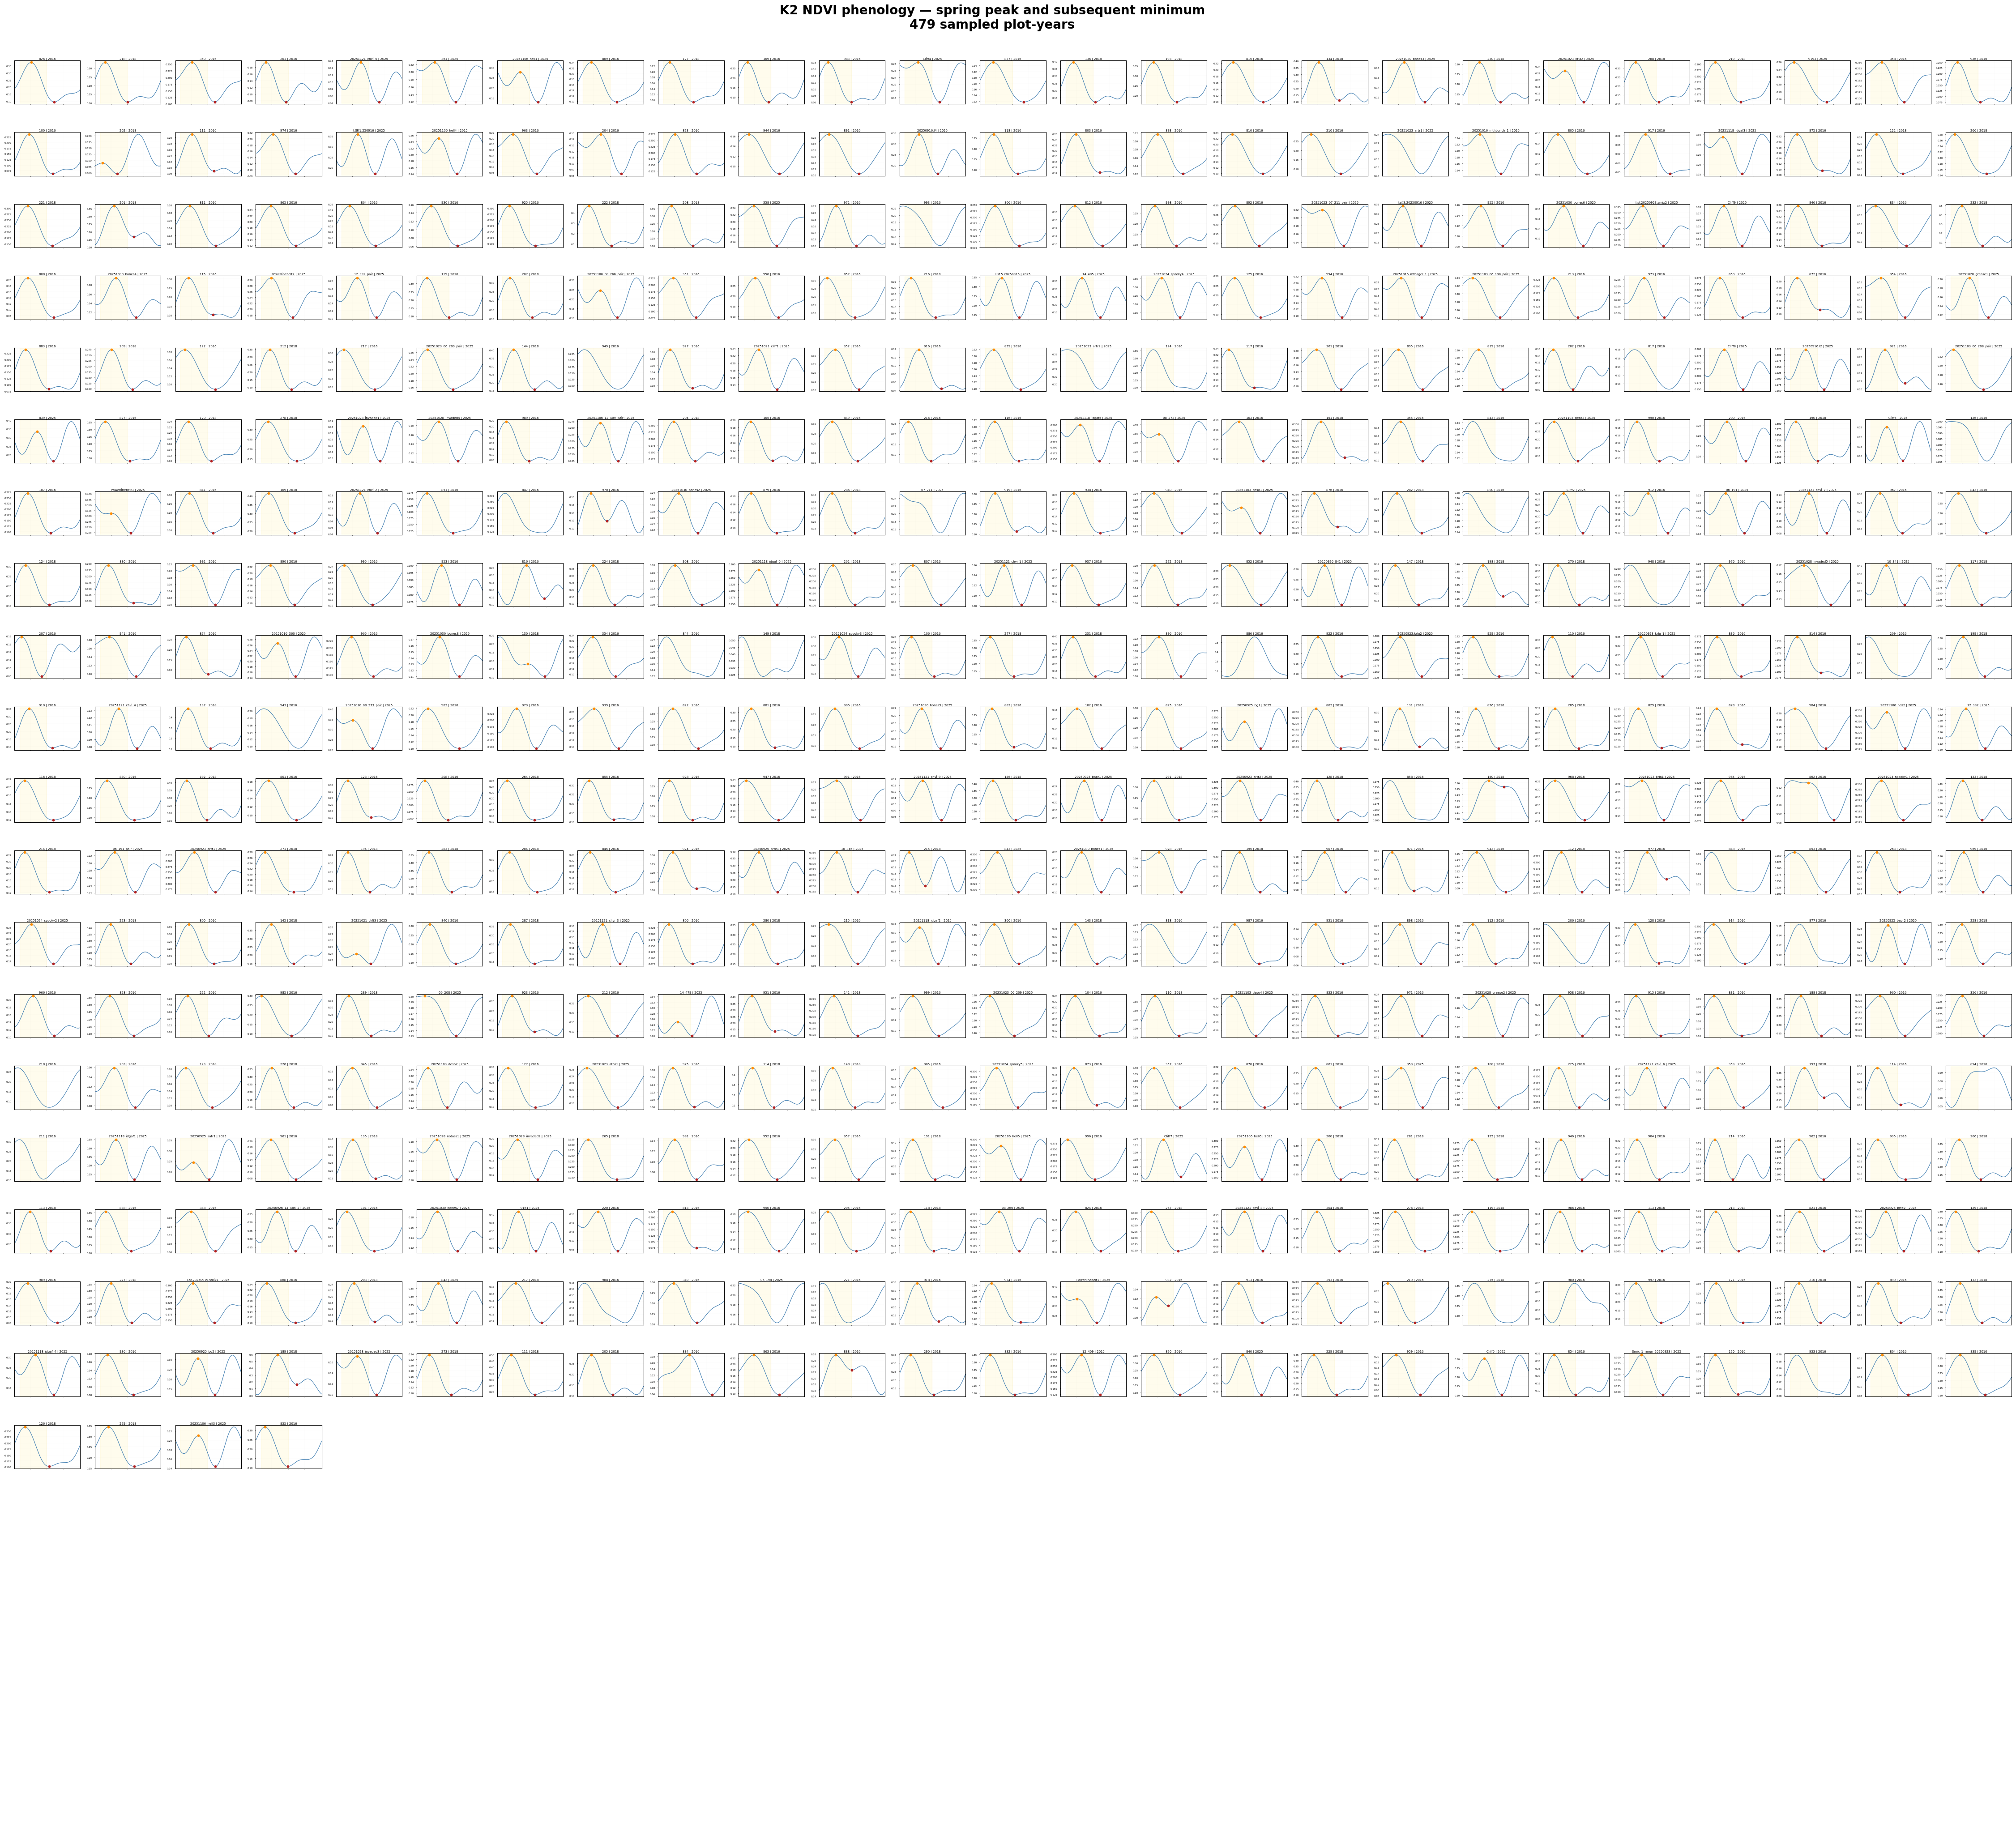

In [10]:

# ============================================================
# K2 NDVI — 25 × 25 PLOT PHENOLOGY QC MATRIX
# Uses existing FirstSpringPeak notebook objects
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

NROWS = 25
NCOLS = 25
N_PANELS = NROWS * NCOLS

RANDOM_SAMPLE = True
RANDOM_SEED = 42

# Use existing plot-level results
df = plot_features.copy()

if RANDOM_SAMPLE:
    df = df.sample(
        n=min(N_PANELS, len(df)),
        random_state=RANDOM_SEED
    )
else:
    # Put failed phenology detections first for QC
    df = df.sort_values(
        ["valid_spring_decline", YEAR_COL],
        ascending=[True, True]
    ).head(N_PANELS)

fig, axes = plt.subplots(
    NROWS,
    NCOLS,
    figsize=(46, 42),
    sharex=True,
    sharey=False
)

axes = axes.ravel()

for ax, (_, rec) in zip(axes, df.iterrows()):

    # Existing reconstruction function
    v = reconstruct_ndvi(rec)

    ax.plot(
        DOY,
        v,
        color="steelblue",
        linewidth=0.85
    )

    # Highlight predefined spring search window
    ax.axvspan(
        *SPRING_PEAK_WINDOW,
        color="gold",
        alpha=0.07
    )

    # Existing peak and subsequent minimum
    if rec["valid_spring_decline"]:

        peak = int(rec["spring_peak_doy"])
        minimum = int(rec["summer_min_doy"])

        ax.scatter(
            peak,
            v[peak - 1],
            color="darkorange",
            s=10,
            zorder=3
        )

        ax.scatter(
            minimum,
            v[minimum - 1],
            color="firebrick",
            s=10,
            zorder=3
        )

    ax.set_xlim(1, 365)
    ax.set_xticks([90, 180, 270])

    ax.tick_params(
        axis="both",
        labelsize=4,
        length=1
    )

    ax.set_title(
        f"{rec[PLOT_ID_COL]} | {int(rec[YEAR_COL])}",
        fontsize=5,
        pad=1
    )

    ax.grid(alpha=0.12, linewidth=0.3)

# Hide unused panels
for ax in axes[len(df):]:
    ax.axis("off")

fig.suptitle(
    "K2 NDVI phenology — spring peak and subsequent minimum\n"
    f"{len(df)} sampled plot-years",
    fontsize=20,
    fontweight="bold",
    y=0.995
)

fig.subplots_adjust(
    left=0.025,
    right=0.995,
    bottom=0.025,
    top=0.965,
    hspace=0.65,
    wspace=0.22
)

plt.show()


Total phenology plot-years: 479
Matched K5 assignments: 479
Unmatched plot-years: 0

Plot-years by K5 parent:


C:\Users\scottfordham\AppData\Local\Temp\ipykernel_11932\2576824796.py:38: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  k5["_join_plot"] = k5[k5_id_col].map(normalize_plot_id)
C:\Users\scottfordham\AppData\Local\Temp\ipykernel_11932\2576824796.py:39: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  k5["_join_year"] = pd.to_numeric(k5["Year"], errors="coerce")


,,n
parent_cluster_k5,parent_label,
1,PBG,109
2,ARTR,36
3,Non-ARTR shrub,109
4,Exotic forb,93
5,EAG,132


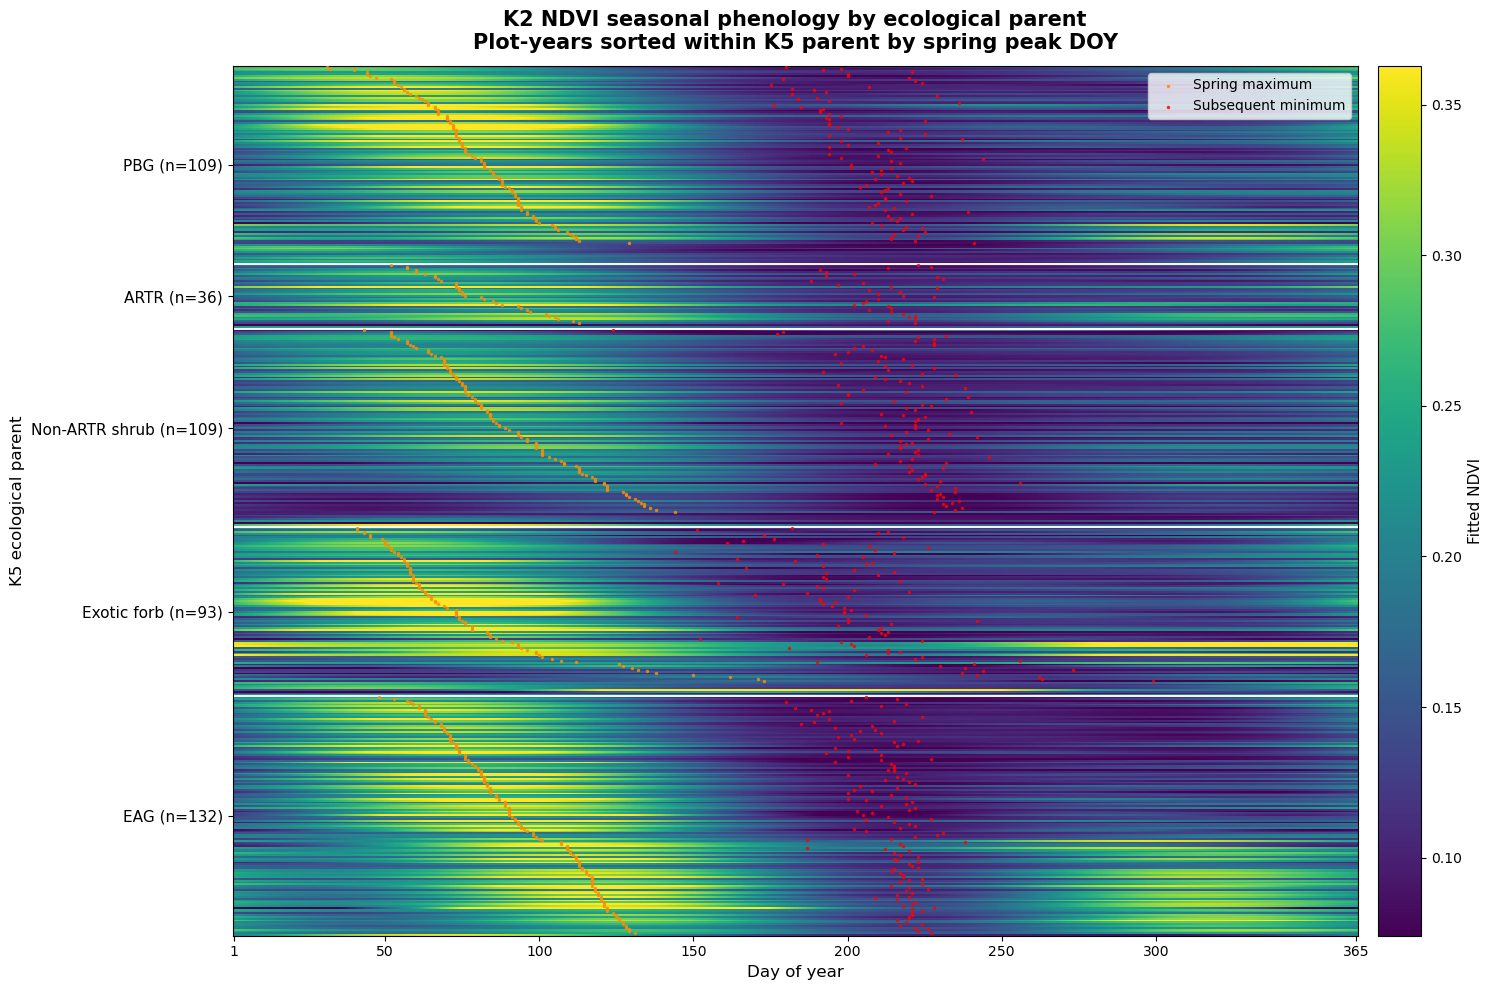


Heatmap complete: 479 plot-years across 5 K5 parents.


In [14]:

# ============================================================
# K2 NDVI PHENOLOGY HEATMAP — K5 ECOLOGICAL PARENTS
# Sorted by parent state, then spring peak DOY
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. K5 parent assignments
# ------------------------------------------------------------

K5_CSV = Path(
    r"C:\NCA_DATA\Vegetation Data\Clustering_Veg\K5_m1p33\Derived"
    r"\NCA_FCM_K5_m1p33_parent_assignments.csv"
)

K5_NAMES = {
    1: "PBG",
    2: "ARTR",
    3: "Non-ARTR shrub",
    4: "Exotic forb",
    5: "EAG",
}

k5 = pd.read_csv(K5_CSV, low_memory=False)

k5_id_col = "Plot" if "Plot" in k5.columns else "PlotID"

def normalize_plot_id(value):
    if pd.isna(value):
        return pd.NA
    s = str(value).strip()
    return s[:-2] if s.endswith(".0") else s

k5["_join_plot"] = k5[k5_id_col].map(normalize_plot_id)
k5["_join_year"] = pd.to_numeric(k5["Year"], errors="coerce")
k5["parent_cluster_k5"] = pd.to_numeric(
    k5["parent_cluster_k5"], errors="coerce"
)

k5_join = (
    k5[["_join_plot", "_join_year", "parent_cluster_k5"]]
    .dropna(subset=["_join_plot", "_join_year"])
    .copy()
)

if k5_join.duplicated(["_join_plot", "_join_year"]).any():
    raise ValueError(
        "Duplicate PlotID-Year combinations in K5 assignment table."
    )

# ------------------------------------------------------------
# 2. Join K5 labels to existing NDVI phenology results
# ------------------------------------------------------------

df = plot_features.copy()

df["_join_plot"] = df[PLOT_ID_COL].map(normalize_plot_id)
df["_join_year"] = pd.to_numeric(
    df[YEAR_COL], errors="coerce"
)

# Avoid collisions if rerunning the cell
df = df.drop(
    columns=["parent_cluster_k5", "parent_label"],
    errors="ignore"
)

df = df.merge(
    k5_join,
    on=["_join_plot", "_join_year"],
    how="left",
    validate="many_to_one",
)

print(f"Total phenology plot-years: {len(df)}")
print(
    "Matched K5 assignments:",
    df["parent_cluster_k5"].notna().sum()
)
print(
    "Unmatched plot-years:",
    df["parent_cluster_k5"].isna().sum()
)

df = df[
    df["parent_cluster_k5"].isin(K5_NAMES)
].copy()

if df.empty:
    raise ValueError(
        "No K5 assignments matched. Check PlotID and Year keys."
    )

df["parent_cluster_k5"] = (
    df["parent_cluster_k5"].astype(int)
)
df["parent_label"] = (
    df["parent_cluster_k5"].map(K5_NAMES)
)

df = df.sort_values(
    ["parent_cluster_k5", "spring_peak_doy", YEAR_COL],
    na_position="last"
).reset_index(drop=True)

print("\nPlot-years by K5 parent:")
display(
    df.groupby(
        ["parent_cluster_k5", "parent_label"]
    ).size().rename("n").to_frame()
)

# ------------------------------------------------------------
# 3. Reconstruct NDVI trajectories using existing function
# ------------------------------------------------------------

curves = np.vstack([
    reconstruct_ndvi(rec)
    for _, rec in df.iterrows()
])

if curves.shape[1] != len(DOY):
    raise ValueError(
        "Reconstruction length does not match DOY array."
    )

# ------------------------------------------------------------
# 4. Group boundaries and positions
# ------------------------------------------------------------

counts = (
    df.groupby("parent_cluster_k5", sort=True)
    .size()
)

ends = counts.cumsum().to_numpy()
starts = np.r_[0, ends[:-1]]
centers = (starts + ends) / 2

group_labels = [
    f"{K5_NAMES[k]} (n={n})"
    for k, n in counts.items()
]

# ------------------------------------------------------------
# 5. Heatmap
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(16, 10))

im = ax.imshow(
    curves,
    cmap="viridis",
    aspect="auto",
    interpolation="nearest",
    origin="upper",
    extent=[
        float(DOY[0]) - 0.5,
        float(DOY[-1]) + 0.5,
        len(df),
        0
    ],
    vmin=np.nanpercentile(curves, 2),
    vmax=np.nanpercentile(curves, 98),
)

# ------------------------------------------------------------
# 6. Spring peak and summer minimum overlays
# ------------------------------------------------------------

row_y = np.arange(len(df)) + 0.5

valid = (
    df["valid_spring_decline"]
    .fillna(False)
    .to_numpy(dtype=bool)
)

for col, color, marker_label in [
    ("spring_peak_doy", "darkorange", "Spring maximum"),
    ("summer_min_doy", "red", "Subsequent minimum"),
]:

    values = pd.to_numeric(
        df[col], errors="coerce"
    ).to_numpy(dtype=float)

    # Create a NEW boolean array; do not modify a read-only view.
    good = valid & np.isfinite(values)

    ax.scatter(
        values[good],
        row_y[good],
        color=color,
        s=6,
        linewidths=0,
        alpha=0.85,
        label=marker_label,
        zorder=3,
    )

# ------------------------------------------------------------
# 7. K5 class separators
# ------------------------------------------------------------

for boundary in ends[:-1]:
    ax.axhline(
        boundary,
        color="white",
        linewidth=1.5,
        alpha=0.95
    )

ax.set_yticks(centers)
ax.set_yticklabels(group_labels, fontsize=11)

ax.set_xticks([1, 50, 100, 150, 200, 250, 300, 365])

ax.set_xlabel("Day of year", fontsize=12)
ax.set_ylabel("K5 ecological parent", fontsize=12)

ax.set_title(
    "K2 NDVI seasonal phenology by ecological parent\n"
    "Plot-years sorted within K5 parent by spring peak DOY",
    fontsize=15,
    fontweight="bold",
    pad=12
)

cbar = fig.colorbar(im, ax=ax, pad=0.015)
cbar.set_label("Fitted NDVI", fontsize=11)

ax.legend(
    loc="upper right",
    frameon=True,
    fontsize=10
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. Keep joined records available for further diagnostics
# ------------------------------------------------------------

plot_features_k5 = df.copy()

print(
    f"\nHeatmap complete: {len(df)} plot-years "
    f"across {len(counts)} K5 parents."
)


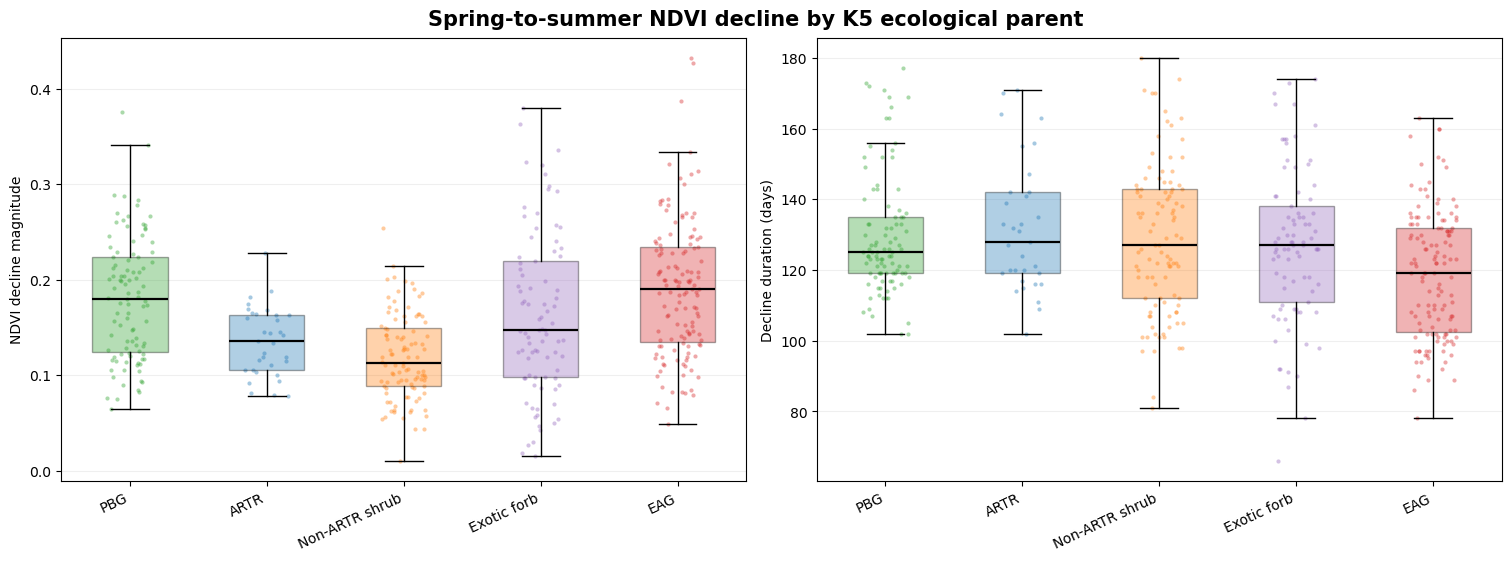

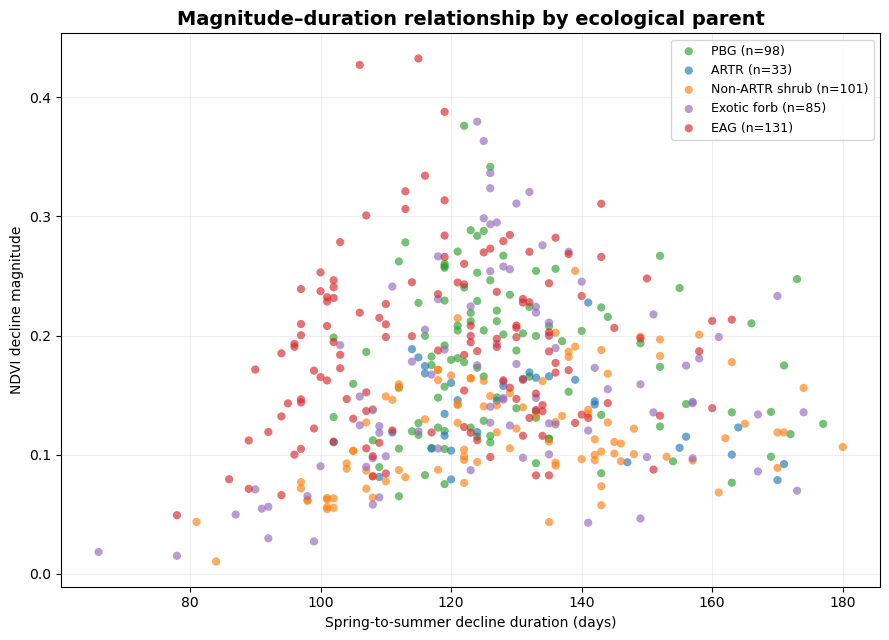

,,n,magnitude_median,magnitude_q25,magnitude_q75,duration_median,duration_q25,duration_q75
parent_cluster_k5,parent_label,,,,,,,
1,PBG,98,0.180,0.124,0.224,125.0,119.0,135.0
2,ARTR,33,0.136,0.106,0.164,128.0,119.0,142.0
3,Non-ARTR shrub,101,0.113,0.088,0.149,127.0,112.0,143.0
4,Exotic forb,85,0.148,0.098,0.219,127.0,111.0,138.0
5,EAG,131,0.190,0.135,0.234,119.0,102.5,132.0


In [15]:

# ============================================================
# K5 PHENOLOGY — DECLINE MAGNITUDE AND DURATION
# Class distributions and joint feature space
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

df = plot_features_k5.copy()

FEATURES = [
    "decline_magnitude_ndvi",
    "decline_duration_days"
]

K5_ORDER = [1, 2, 3, 4, 5]
K5_COLORS = {
    1: "#2ca02c",  # PBG
    2: "#1f77b4",  # ARTR
    3: "#ff7f0e",  # Non-ARTR shrub
    4: "#9467bd",  # Exotic forb
    5: "#d62728",  # EAG
}

df = df.loc[
    df["valid_spring_decline"].fillna(False)
].copy()

for col in FEATURES:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=FEATURES)

rng = np.random.default_rng(42)

# ------------------------------------------------------------
# FIGURE 1 — FEATURE DISTRIBUTIONS BY PARENT
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2, figsize=(15, 5.5),
    constrained_layout=True
)

for ax, feature, ylabel in zip(
    axes,
    FEATURES,
    ["NDVI decline magnitude", "Decline duration (days)"]
):
    groups = [
        df.loc[df["parent_cluster_k5"] == k, feature].to_numpy()
        for k in K5_ORDER
    ]

    bp = ax.boxplot(
        groups,
        positions=np.arange(1, 6),
        widths=0.55,
        patch_artist=True,
        showfliers=False,
        medianprops={"color": "black", "linewidth": 1.6}
    )

    for patch, k in zip(bp["boxes"], K5_ORDER):
        patch.set_facecolor(K5_COLORS[k])
        patch.set_alpha(0.35)

    # Plot individual observations
    for i, (values, k) in enumerate(zip(groups, K5_ORDER), start=1):
        jitter = rng.uniform(-0.17, 0.17, len(values))
        ax.scatter(
            np.full(len(values), i) + jitter,
            values,
            s=9,
            color=K5_COLORS[k],
            alpha=0.4,
            linewidths=0,
            rasterized=True
        )

    ax.set_xticks(
        range(1, 6),
        [K5_NAMES[k] for k in K5_ORDER],
        rotation=25,
        ha="right"
    )
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

fig.suptitle(
    "Spring-to-summer NDVI decline by K5 ecological parent",
    fontsize=15,
    fontweight="bold"
)

plt.show()

# ------------------------------------------------------------
# FIGURE 2 — DECLINE MAGNITUDE VS DURATION
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 6.5))

for k in K5_ORDER:
    subset = df.loc[df["parent_cluster_k5"] == k]

    ax.scatter(
        subset["decline_duration_days"],
        subset["decline_magnitude_ndvi"],
        s=35,
        alpha=0.65,
        color=K5_COLORS[k],
        edgecolors="none",
        label=f"{K5_NAMES[k]} (n={len(subset)})"
    )

ax.set_xlabel("Spring-to-summer decline duration (days)")
ax.set_ylabel("NDVI decline magnitude")
ax.set_title(
    "Magnitude–duration relationship by ecological parent",
    fontsize=14,
    fontweight="bold"
)

ax.grid(alpha=0.2)
ax.legend(frameon=True, fontsize=9)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# CLASS-LEVEL DESCRIPTIVE SUMMARY
# ------------------------------------------------------------

summary = (
    df.groupby(["parent_cluster_k5", "parent_label"])
      .agg(
          n=("decline_magnitude_ndvi", "size"),
          magnitude_median=("decline_magnitude_ndvi", "median"),
          magnitude_q25=("decline_magnitude_ndvi",
                         lambda x: x.quantile(0.25)),
          magnitude_q75=("decline_magnitude_ndvi",
                         lambda x: x.quantile(0.75)),
          duration_median=("decline_duration_days", "median"),
          duration_q25=("decline_duration_days",
                        lambda x: x.quantile(0.25)),
          duration_q75=("decline_duration_days",
                        lambda x: x.quantile(0.75))
      )
      .round(3)
)

display(summary)


## Interpretation, limitations, and QC

- **First qualifying spring maximum:** The first local NDVI maximum in DOY 30–180 whose decline to the **next local minimum** is at least 10% of the reconstructed annual NDVI range. The next minimum must be before DOY 300 and within 180 days. These are *exploratory, prespecified algorithm thresholds*, not validated ecological phenophase definitions.
- **No qualifying event:** Metrics are `NaN`, not forced from the global maximum or a year-boundary extremum. Inspect the fraction excluded and how exclusion differs among vegetation states and years before using these features in ML.
- **Decline duration is NOT growing-season length.** It measures days between the selected first spring maximum and subsequent minimum. Rates are calculated from the fitted curve, not raw observations.
- **Phase convention:** Confirm `PHASE_CONVENTION`, units, and time origin against the Earth Engine export by comparing reconstructed trajectories with *observed NDVI* at known plots. Coherent-looking curves alone are insufficient.
- **Spatial support:** Point sampling of the TIFF may not match buffer-aggregated training features. This matters if derived features are later joined to classifier rows.
- **Sampling:** The only pixels sampled are field-plot coordinates. No raster outputs or files are written.
- **2026:** Included in `YEARS` and processed when the matching raster and plot table entries exist.
